---
title: "3.7.b Dengue y clima: la amenaza"
short_title: "b. Amenaza"
subtitle: "Casos notificados 2007–2022, estacionalidad, ventana térmica de transmisión y señales climáticas"
description: "Análisis de los casos de dengue notificados en Leticia (SIVIGILA vía OpenDengue) frente a la temperatura, la lluvia, la humedad y la TSM."
keywords: [dengue, Aedes aegypti, SIVIGILA, OpenDengue, temperatura, El Niño, Leticia]
---

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mromerot/leticia/blob/main/book/03_analisis/37_dengue/b_amenaza.ipynb)

In [1]:
# Preparación del entorno. En Colab instala el paquete del proyecto desde GitHub (1–2 minutos);
# en una copia local usa el paquete ya instalado con `pip install -e .`.
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "leticia @ git+https://github.com/mromerot/leticia"], check=True)
from leticia.libro import preparar, intentar
preparar()

El dengue es una amenaza biológica, pero su transmisión depende del clima: la temperatura acelera el desarrollo del
mosquito *Aedes aegypti* y la replicación del virus, la lluvia y el almacenamiento de agua crean criaderos, y la
humedad prolonga la vida del vector. Este cuaderno describe los casos notificados en Leticia y su relación con el
clima, como paso previo al pronóstico de [3.7.c](c_riesgo.ipynb). Los casos vienen del SIVIGILA del Instituto
Nacional de Salud, compilados y estandarizados por OpenDengue [@clarke2024opendengue].

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from leticia import fuentes, salud, viz
from leticia.config import parametros

pdg = parametros()["dengue"]
semanal = fuentes.dengue_opendengue()
mensual = salud.casos_mensuales(semanal)

## 1. Casos notificados, 2007–2022

Casos notificados 2007–2022: 4.366 . Años con más casos: 2019 (1.716), 2011 (528), 2014 (430).

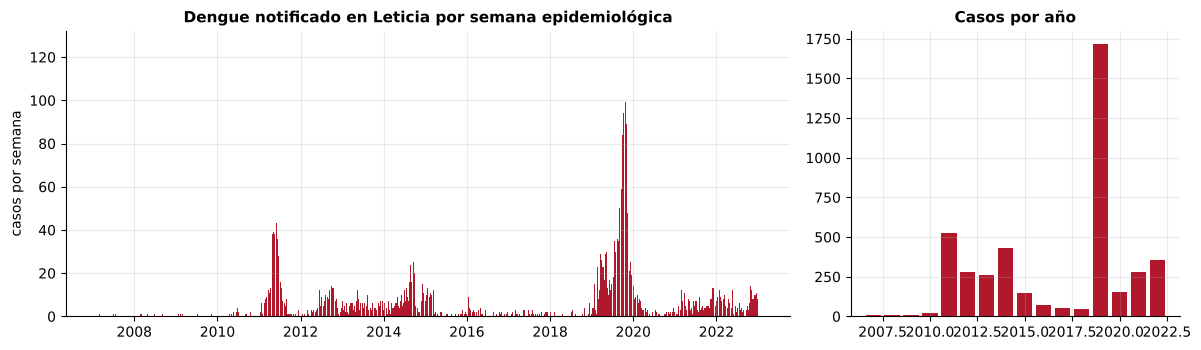

In [3]:
anual = semanal.groupby(semanal.index.year).sum()
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw={"width_ratios": [2.2, 1]})
ax[0].bar(semanal.index, semanal, width=6, color=viz.ROJO)
ax[0].set_ylabel("casos por semana")
ax[0].set_title("Dengue notificado en Leticia por semana epidemiológica")
ax[1].bar(anual.index, anual, color=viz.ROJO)
ax[1].set_title("Casos por año")
fig.tight_layout()
display(Markdown(f"Casos notificados {semanal.index.min():%Y}–{semanal.index.max():%Y}: **{int(semanal.sum()):,}**".replace(",", ".")
                 + f". Años con más casos: " + ", ".join(f"{a} ({int(v):,})".replace(",", ".") for a, v in anual.nlargest(3).items()) + "."))

In [4]:
viz.pie(viz.nota_fuente("dengue_opendengue"))

Fuente: OpenDengue (Clarke et al., 2024) con datos del SIVIGILA – Instituto Nacional de Salud — OpenDengue V1.3, extracto espacial (Colombia a nivel municipal, semanal).

:::{note} Calidad de la serie
De 2007 a 2010 la serie registra menos de 25 casos por año, frente a cientos desde 2011. Es más probable un cambio en
la notificación o en la extracción de los datos que un cambio real en la transmisión, así que los análisis
estadísticos usan **2011–2022**. OpenDengue solo publica las semanas con casos; las semanas sin registro se cuentan
como cero. Los casos notificados subestiman la transmisión: muchos casos leves no consultan.
:::

## 2. Estacionalidad del dengue y del clima

,1,2,3,4,5,6,7,8,9,10,11,12
casos (promedio mensual),20.30,18.20,26.20,26.40,32.30,29.80,29.80,28.60,34.80,60.60,29.40,24.00
lluvia (mm/mes),320.60,304.00,340.50,301.20,260.00,185.00,142.40,137.50,171.80,221.90,240.70,296.80
temperatura media (°C),26.10,26.10,26.20,26.10,25.80,25.40,25.30,25.90,26.30,26.50,26.50,26.20


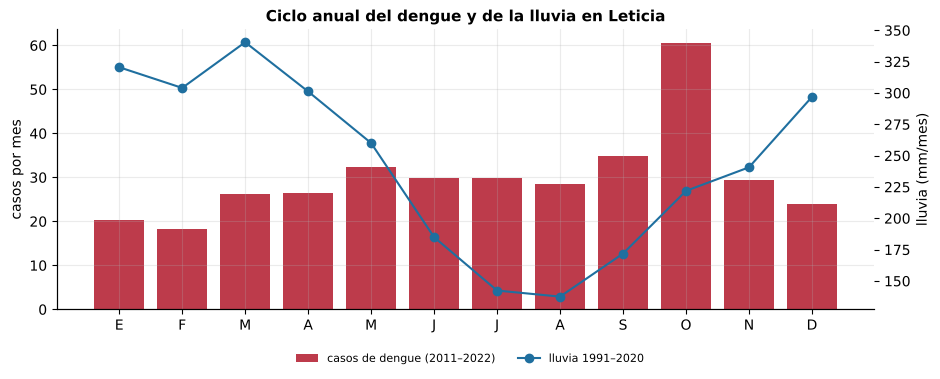

In [5]:
era = fuentes.clima_diario()
base = era.loc["1991":"2020"]
cas = mensual.loc["2011":]
ciclo = pd.DataFrame({
    "casos (promedio mensual)": cas.groupby(cas.index.month).mean(),
    "lluvia (mm/mes)": base["precipitation_sum"].resample("MS").sum().groupby(lambda f: f.month).mean(),
    "temperatura media (°C)": base["temperature_2m_mean"].groupby(base.index.month).mean(),
})
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.bar(ciclo.index, ciclo["casos (promedio mensual)"], color=viz.ROJO, alpha=0.85, label="casos de dengue (2011–2022)")
ax.set_ylabel("casos por mes")
ax2 = ax.twinx()
ax2.plot(ciclo.index, ciclo["lluvia (mm/mes)"], "o-", color=viz.AZUL_RIO, label="lluvia 1991–2020")
ax2.set_ylabel("lluvia (mm/mes)")
ax2.grid(False)
ax.set_xticks(range(1, 13)); ax.set_xticklabels(list("EFMAMJJASOND"))
ax.set_title("Ciclo anual del dengue y de la lluvia en Leticia")
fig.legend(loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.0), fontsize=8)
fig.tight_layout(rect=(0, 0.07, 1, 1))
display(ciclo.round(1).T)

In [6]:
viz.pie(viz.nota_fuente("dengue_opendengue", "clima_diario"))

Fuente: OpenDengue (Clarke et al., 2024) con datos del SIVIGILA – Instituto Nacional de Salud — OpenDengue V1.3, extracto espacial (Colombia a nivel municipal, semanal); ECMWF ERA5 (vía Open-Meteo) — Reanálisis ERA5, celda 0,25°.

**Lectura.** Los casos aumentan a lo largo del año y alcanzan su máximo en **octubre**, cuando termina la temporada
menos lluviosa (junio–septiembre), regresan las lluvias y la temperatura media es la más alta del año. Es un patrón
compatible con la combinación de calor y agua acumulada en recipientes, pero el ciclo promedio mezcla años muy
distintos: el brote de 2019 pesa mucho en los promedios.

## 3. La ventana térmica de la transmisión

Mordecai et al. modelaron la respuesta de cada rasgo del mosquito y del virus a la temperatura y la combinaron en el
número reproductivo R₀. Para *Aedes aegypti*, a temperatura constante, la transmisión es máxima hacia **29,1 °C**,
cae a cero por debajo de 17,8 °C y por encima de 34,6 °C, y es máxima en un rango de 26 a 29 °C
[@mordecai2017]. Leticia está casi todo el año en la parte baja de ese rango óptimo, de modo que un clima algo más
cálido **aumenta** la aptitud para la transmisión.

Porcentaje de meses en cada clase de aptitud térmica, por década:

temperature_2m_mean,subóptima (fresca),máxima transmisión
1970s,67.00,33.00
1980s,73.00,27.00
1990s,63.00,37.00
2000s,38.00,62.00
2010s,40.00,60.00
2020s,44.00,56.00


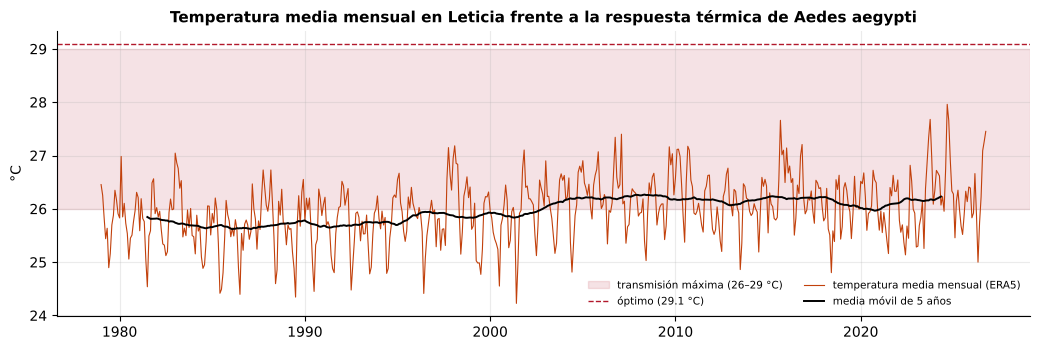

In [7]:
t_mes = era["temperature_2m_mean"].resample("MS").mean().loc["1979":]
clase = salud.aptitud_termica(t_mes, pdg["temperatura_limite_inferior"], tuple(pdg["rango_transmision_maxima"]), pdg["temperatura_limite_superior"])
fig, ax = plt.subplots(figsize=(10.5, 3.6))
ax.axhspan(*pdg["rango_transmision_maxima"], color=viz.ROJO, alpha=0.12, label="transmisión máxima (26–29 °C)")
ax.axhline(pdg["temperatura_optima"], color=viz.ROJO, lw=1, ls="--", label=f"óptimo ({pdg['temperatura_optima']} °C)")
ax.plot(t_mes.index, t_mes, color=viz.CALOR, lw=0.8, label="temperatura media mensual (ERA5)")
ax.plot(t_mes.rolling(60, center=True).mean(), color="k", lw=1.4, label="media móvil de 5 años")
ax.set_ylabel("°C")
ax.set_title("Temperatura media mensual en Leticia frente a la respuesta térmica de Aedes aegypti")
ax.legend(fontsize=7.5, ncol=2, loc="lower right")
fig.tight_layout()
dec = pd.crosstab((t_mes.index.year // 10) * 10, clase, normalize="index").mul(100).round(0)
dec.index = [f"{d}s" for d in dec.index]
display(Markdown("**Porcentaje de meses en cada clase de aptitud térmica, por década:**"))
display(dec)

In [8]:
viz.pie(viz.nota_fuente("clima_diario") + " Respuesta térmica según Mordecai et al. (2017).")

Fuente: ECMWF ERA5 (vía Open-Meteo) — Reanálisis ERA5, celda 0,25°. Respuesta térmica según Mordecai et al. (2017).

**Lectura.** Entre 1970 y 1999 dos de cada tres meses tuvieron una temperatura media por debajo de 26 °C; desde 2000,
más de la mitad de los meses está dentro del rango de transmisión máxima, aunque todavía por debajo del óptimo. La celda de ERA5 está dominada por bosque; en la ciudad, con su
isla de calor ([3.4](../34_calor/index.md)), la temperatura real es mayor. El umbral es de temperatura **constante**:
la variación diaria y los microhábitats del mosquito (tanques, llantas, canaletas) modifican la respuesta.

## 4. Señales climáticas con rezago

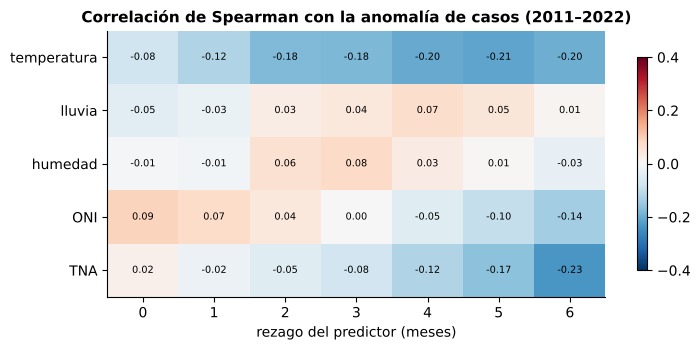

In [9]:
X = salud.predictores_mensuales(era, {"ONI": fuentes.oni(), "TNA": fuentes.indice_tna()}, base=(1991, 2020))
y = salud.anomalia_mensual(np.log1p(cas))
rez = salud.tabla_rezagos(y, X, range(0, 7))
fig, ax = plt.subplots(figsize=(7.5, 3.6))
im = ax.imshow(rez.T.values, cmap="RdBu_r", vmin=-0.4, vmax=0.4, aspect="auto")
ax.set_xticks(range(len(rez.index))); ax.set_xticklabels(rez.index)
ax.set_yticks(range(len(rez.columns))); ax.set_yticklabels(rez.columns)
for i in range(rez.shape[1]):
    for j in range(rez.shape[0]):
        ax.text(j, i, f"{rez.iloc[j, i]:.2f}", ha="center", va="center", fontsize=7)
ax.set_xlabel("rezago del predictor (meses)")
ax.set_title("Correlación de Spearman con la anomalía de casos (2011–2022)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()

In [10]:
viz.pie(viz.nota_fuente("dengue_opendengue", "clima_diario", "indices_oceanicos", "indice_tna")
        + " Anomalías estandarizadas por mes calendario; casos en escala log(1 + casos).")

Fuente: OpenDengue (Clarke et al., 2024) con datos del SIVIGILA – Instituto Nacional de Salud — OpenDengue V1.3, extracto espacial (Colombia a nivel municipal, semanal); ECMWF ERA5 (vía Open-Meteo) — Reanálisis ERA5, celda 0,25°; NOAA Climate Prediction Center — ONI (ERSSTv5), trimestres móviles 1950–presente; NOAA Physical Sciences Laboratory — TNA mensual (HadISST1.1, climatología 1991–2020), 1948–presente. Anomalías estandarizadas por mes calendario; casos en escala log(1 + casos).

**Lectura.** Las correlaciones entre el clima de un mes y los casos de los meses siguientes son **débiles** (menores
de 0,25 en valor absoluto). En Leticia el dengue depende tanto o más de la inmunidad de la población, del serotipo
que circula y de la movilidad en la triple frontera que del clima del mes anterior. La sección [3.7.c](c_riesgo.ipynb)
evalúa si estas señales, aun débiles, mejoran un pronóstico.